# Step 9 — Hybrid forecasting strategy

Evaluate three specified policies using **saved Step 7 June forecasts** and the **unchanged Step 8 financial assumptions**. No models are retrained.

**Methodological limit:** the hybrid (Harbour → naive; Garden/Uptown → XGBoost) was proposed after seeing June. Its June score is exploratory and cannot establish independent out-of-sample superiority or actual savings. No branch rule is optimized in this notebook.

In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from hybrid_forecasting_strategy import run, POLICIES
from forecast_business_value import sha
DATA=Path(os.environ.get('STORIES_DATA','/Users/aya/Downloads/stories_transactions.csv'))
PREDICTIONS=ROOT/'artifacts/daily_demand_models/test_predictions.csv'
OUT=ROOT/'reports/hybrid_forecasting'
locked=[DATA,PREDICTIONS,*sorted((ROOT/'artifacts/daily_demand_models').glob('*')),
        *sorted(p for p in (ROOT/'reports/forecast_business_value').iterdir() if p.is_file()),
        ROOT/'reports/demand_forecasting/selection_lock.json']
before={str(p):sha(p) for p in locked}
display(pd.DataFrame(POLICIES).rename_axis('Branch'))
print('No model loading or fitting. No selection from validation or June in this run.')

No model loading or fitting. No selection from validation or June in this run.


,A_AllNaive,B_AllXGBoost,C_Hybrid
Branch,,,
Garden,Seasonal naive,XGBoost,XGBoost
Harbour,Seasonal naive,XGBoost,Seasonal naive
Uptown,Seasonal naive,XGBoost,XGBoost


## 1. Frozen observations and hypothetical economics

Every policy scores June 1–30, three branches: **90 identical branch-days**. These are rolling next-day forecasts after yesterday closes, not one forecast of all June.

Capacity = `floor(forecast + 0.5)` transaction-equivalents. Shortage cost per missed transaction = 25%, 50%, or 100% of Jan–May branch GP/transaction. Excess cost per unused transaction-equivalent = 10%, 25%, or 50% of Jan–May recorded branch input cost/transaction. Score all nine cross-products.

`Total decision cost = shortage × assumed shortage penalty + excess × assumed excess penalty`.

Recorded GP and input costs are accounting inputs; these penalty fractions are assumptions. Lost sales, waste, salvage and service effects are not observed. The result is not net operating profit or actual cash saved.

In [2]:
economics=pd.read_csv(ROOT/'reports/forecast_business_value/historical_economics.csv')
display(economics[economics.Period=='Jan-May calibration'].round(4))
unit_costs=pd.read_csv(ROOT/'reports/forecast_business_value/scenario_unit_costs.csv')
display(unit_costs.sort_values(['ShortageFraction','WasteFraction','Branch']).round(4))
predictions=pd.read_csv(PREDICTIONS,parse_dates=['Date'])
display(predictions.groupby('Branch').agg(BranchDays=('Date','size'),Transactions=('Transactions','sum')))
print('Saved forecasts:',len(predictions),'branch-days')

Saved forecasts: 90 branch-days


,Branch,Transactions,RecordedGPUSD,RecordedRevenueUSD,RecordedInputCostUSD,Period,GPPerTransactionUSD,InputCostPerTransactionUSD
0,Garden,8912,37379.76,79613.19,42233.43,Jan-May calibration,4.1943,4.7389
1,Harbour,12948,77249.43,118893.18,41643.75,Jan-May calibration,5.9661,3.2162
2,Uptown,5121,28026.31,44776.68,16750.37,Jan-May calibration,5.4728,3.2709


,Scenario,Branch,ShortageFraction,WasteFraction,ShortageUnitCostUSD,WasteUnitCostUSD
0,S0.25_W0.1,Garden,0.25,0.10,1.0486,0.4739
1,S0.25_W0.1,Harbour,0.25,0.10,1.4915,0.3216
2,S0.25_W0.1,Uptown,0.25,0.10,1.3682,0.3271
3,S0.25_W0.25,Garden,0.25,0.25,1.0486,1.1847
4,S0.25_W0.25,Harbour,0.25,0.25,1.4915,0.8041
5,S0.25_W0.25,Uptown,0.25,0.25,1.3682,0.8177
6,S0.25_W0.5,Garden,0.25,0.50,1.0486,2.3695
7,S0.25_W0.5,Harbour,0.25,0.50,1.4915,1.6081
8,S0.25_W0.5,Uptown,0.25,0.50,1.3682,1.6355
9,S0.5_W0.1,Garden,0.50,0.10,2.0972,0.4739


,BranchDays,Transactions
Branch,,
Garden,30,2251
Harbour,30,3386
Uptown,30,1269


## 2. Evaluate the three fixed policies

The runner checks source/prediction fingerprints, reconciles saved targets to original unique transactions, verifies historical economics and reproduces Step 8 cost components before combining branches. No tuning, safety buffers or branch search. Daily decisions stay in ignored `artifacts/hybrid_forecasting/`; aggregate evidence is saved in `reports/hybrid_forecasting/`.

In [3]:
findings=run(DATA,PREDICTIONS)
costs=pd.read_csv(OUT/'decision_costs.csv')
comparison=pd.read_csv(OUT/'model_comparison.csv')
print('Independent validation:',findings['independentOutOfSampleValidation'])
print('Actual savings measured:',findings['actualSavingsMeasured'])

   Scenario  AllNaiveCostUSD  AllXGBoostCostUSD  HybridCostUSD  HybridImprovementVsBestUniformUSD
 S0.25_W0.1           761.25             837.34         716.60                              44.65
S0.25_W0.25           991.66            1017.72         941.85                              49.81
 S0.25_W0.5          1375.67            1318.36        1317.27                               1.09
  S0.5_W0.1          1368.90            1554.42        1283.04                              85.87
 S0.5_W0.25          1599.31            1734.80        1508.29                              91.02
  S0.5_W0.5          1983.32            2035.44        1883.70                              99.62
    S1_W0.1          2584.20            2988.57        2415.91                             168.30
   S1_W0.25          2814.61            3168.96        2641.16                             173.45
    S1_W0.5          3198.62            3469.60        3016.57                             182.05
PASS: unchanged Step

## 3. Overall June costs, paired improvements and winner

Positive improvement means the hybrid has lower assumed cost. Compare to **both** uniform policies and to the stronger uniform policy in each scenario. That per-scenario stronger baseline is a descriptive June comparator, not an independently chosen deployment rule. All figures are totals for June; scenario rows are alternatives and must not be added together.

In [4]:
overall=comparison[comparison.Branch=='ALL'].sort_values(['ShortageFraction','WasteFraction'])
display(overall.round(4))
display(costs[costs.Branch=='ALL'][['Scenario','Policy','ShortageCostUSD','OverPreparationCostUSD','TotalDecisionCostUSD']].round(2))
print('Hybrid strictly lower cost than both uniform policies in',findings['overallHybridWins'],'of 9 scenarios.')

Hybrid strictly lower cost than both uniform policies in 9 of 9 scenarios.


,Branch,Scenario,ShortageFraction,WasteFraction,AllNaiveCostUSD,AllXGBoostCostUSD,HybridCostUSD,HybridImprovementVsNaiveUSD,HybridImprovementVsXGBoostUSD,BestUniformCostUSD,HybridImprovementVsBestUniformUSD,HybridReductionVsBestUniformFraction,BestPolicy,StrongestUniformBaseline
0,ALL,S0.25_W0.1,0.25,0.10,761.2539,837.3351,716.6013,44.6526,120.7338,761.2539,44.6526,0.0587,C_Hybrid,A_AllNaive
1,ALL,S0.25_W0.25,0.25,0.25,991.6607,1017.7180,941.8506,49.8101,75.8674,991.6607,49.8101,0.0502,C_Hybrid,A_AllNaive
2,ALL,S0.25_W0.5,0.25,0.50,1375.6721,1318.3561,1317.2661,58.4060,1.0900,1318.3561,1.0900,0.0008,C_Hybrid,B_AllXGBoost
3,ALL,S0.5_W0.1,0.50,0.10,1368.9033,1554.4150,1283.0365,85.8668,271.3785,1368.9033,85.8668,0.0627,C_Hybrid,A_AllNaive
4,ALL,S0.5_W0.25,0.50,0.25,1599.3101,1734.7979,1508.2858,91.0243,226.5121,1599.3101,91.0243,0.0569,C_Hybrid,A_AllNaive
5,ALL,S0.5_W0.5,0.50,0.50,1983.3214,2035.4360,1883.7012,99.6202,151.7348,1983.3214,99.6202,0.0502,C_Hybrid,A_AllNaive
6,ALL,S1_W0.1,1.00,0.10,2584.2020,2988.5748,2415.9068,168.2953,572.6680,2584.2020,168.2953,0.0651,C_Hybrid,A_AllNaive
7,ALL,S1_W0.25,1.00,0.25,2814.6088,3168.9577,2641.1560,173.4528,527.8016,2814.6088,173.4528,0.0616,C_Hybrid,A_AllNaive
8,ALL,S1_W0.5,1.00,0.50,3198.6202,3469.5958,3016.5715,182.0487,453.0243,3198.6202,182.0487,0.0569,C_Hybrid,A_AllNaive


,Scenario,Policy,ShortageCostUSD,OverPreparationCostUSD,TotalDecisionCostUSD
0,S0.25_W0.1,A_AllNaive,607.65,153.60,761.25
1,S0.25_W0.1,B_AllXGBoost,717.08,120.26,837.34
2,S0.25_W0.1,C_Hybrid,566.44,150.17,716.60
3,S0.25_W0.25,A_AllNaive,607.65,384.01,991.66
4,S0.25_W0.25,B_AllXGBoost,717.08,300.64,1017.72
5,S0.25_W0.25,C_Hybrid,566.44,375.42,941.85
6,S0.25_W0.5,A_AllNaive,607.65,768.02,1375.67
7,S0.25_W0.5,B_AllXGBoost,717.08,601.28,1318.36
8,S0.25_W0.5,C_Hybrid,566.44,750.83,1317.27
9,S0.5_W0.1,A_AllNaive,1215.30,153.60,1368.90


## 4. Branch-level costs and ties

Hybrid equals all-naive at Harbour. Hybrid equals all-XGBoost at Garden and Uptown. Report ties explicitly rather than crediting hybrid with an independent branch-level improvement.

In [5]:
for branch in ['Garden','Harbour','Uptown']:
    display(Markdown('### '+branch))
    display(comparison[comparison.Branch==branch].sort_values(['ShortageFraction','WasteFraction']).round(4))
    display(costs[costs.Branch==branch][['Scenario','Policy','ShortageCostUSD','OverPreparationCostUSD','TotalDecisionCostUSD']].round(2))

### Garden

,Branch,Scenario,ShortageFraction,WasteFraction,AllNaiveCostUSD,AllXGBoostCostUSD,HybridCostUSD,HybridImprovementVsNaiveUSD,HybridImprovementVsXGBoostUSD,BestUniformCostUSD,HybridImprovementVsBestUniformUSD,HybridReductionVsBestUniformFraction,BestPolicy,StrongestUniformBaseline
9,Garden,S0.25_W0.1,0.25,0.10,232.2630,197.1559,197.1559,35.1071,0.0,197.1559,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
10,Garden,S0.25_W0.25,0.25,0.25,343.1541,315.1555,315.1555,27.9987,0.0,315.1555,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
11,Garden,S0.25_W0.5,0.25,0.50,527.9728,511.8215,511.8215,16.1513,0.0,511.8215,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
12,Garden,S0.5_W0.1,0.50,0.10,390.5985,315.6454,315.6454,74.9531,0.0,315.6454,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
13,Garden,S0.5_W0.25,0.50,0.25,501.4896,433.6449,433.6449,67.8447,0.0,433.6449,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
14,Garden,S0.5_W0.5,0.50,0.50,686.3083,630.3109,630.3109,55.9973,0.0,630.3109,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
15,Garden,S1_W0.1,1.00,0.10,707.2694,552.6243,552.6243,154.6451,0.0,552.6243,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
16,Garden,S1_W0.25,1.00,0.25,818.1606,670.6239,670.6239,147.5367,0.0,670.6239,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
17,Garden,S1_W0.5,1.00,0.50,1002.9793,867.2899,867.2899,135.6894,0.0,867.2899,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost


,Scenario,Policy,ShortageCostUSD,OverPreparationCostUSD,TotalDecisionCostUSD
27,S0.25_W0.1,A_AllNaive,158.34,73.93,232.26
30,S0.25_W0.1,B_AllXGBoost,118.49,78.67,197.16
33,S0.25_W0.1,C_Hybrid,118.49,78.67,197.16
36,S0.25_W0.25,A_AllNaive,158.34,184.82,343.15
39,S0.25_W0.25,B_AllXGBoost,118.49,196.67,315.16
42,S0.25_W0.25,C_Hybrid,118.49,196.67,315.16
45,S0.25_W0.5,A_AllNaive,158.34,369.64,527.97
48,S0.25_W0.5,B_AllXGBoost,118.49,393.33,511.82
51,S0.25_W0.5,C_Hybrid,118.49,393.33,511.82
54,S0.5_W0.1,A_AllNaive,316.67,73.93,390.60


### Harbour

,Branch,Scenario,ShortageFraction,WasteFraction,AllNaiveCostUSD,AllXGBoostCostUSD,HybridCostUSD,HybridImprovementVsNaiveUSD,HybridImprovementVsXGBoostUSD,BestUniformCostUSD,HybridImprovementVsBestUniformUSD,HybridReductionVsBestUniformFraction,BestPolicy,StrongestUniformBaseline
18,Harbour,S0.25_W0.1,0.25,0.10,334.1794,454.9132,334.1794,0.0,120.7338,334.1794,0.0,0.0,A_AllNaive + C_Hybrid,A_AllNaive
19,Harbour,S0.25_W0.25,0.25,0.25,403.6500,479.5174,403.6500,0.0,75.8674,403.6500,0.0,0.0,A_AllNaive + C_Hybrid,A_AllNaive
20,Harbour,S0.25_W0.5,0.25,0.50,519.4343,520.5243,519.4343,0.0,1.0900,519.4343,0.0,0.0,A_AllNaive + C_Hybrid,A_AllNaive
21,Harbour,S0.5_W0.1,0.50,0.10,622.0451,893.4236,622.0451,0.0,271.3785,622.0451,0.0,0.0,A_AllNaive + C_Hybrid,A_AllNaive
22,Harbour,S0.5_W0.25,0.50,0.25,691.5157,918.0278,691.5157,0.0,226.5121,691.5157,0.0,0.0,A_AllNaive + C_Hybrid,A_AllNaive
23,Harbour,S0.5_W0.5,0.50,0.50,807.3000,959.0347,807.3000,0.0,151.7348,807.3000,0.0,0.0,A_AllNaive + C_Hybrid,A_AllNaive
24,Harbour,S1_W0.1,1.00,0.10,1197.7765,1770.4445,1197.7765,0.0,572.6680,1197.7765,0.0,0.0,A_AllNaive + C_Hybrid,A_AllNaive
25,Harbour,S1_W0.25,1.00,0.25,1267.2471,1795.0487,1267.2471,0.0,527.8016,1267.2471,0.0,0.0,A_AllNaive + C_Hybrid,A_AllNaive
26,Harbour,S1_W0.5,1.00,0.50,1383.0314,1836.0556,1383.0314,0.0,453.0243,1383.0314,0.0,0.0,A_AllNaive + C_Hybrid,A_AllNaive


,Scenario,Policy,ShortageCostUSD,OverPreparationCostUSD,TotalDecisionCostUSD
28,S0.25_W0.1,A_AllNaive,287.87,46.31,334.18
31,S0.25_W0.1,B_AllXGBoost,438.51,16.40,454.91
34,S0.25_W0.1,C_Hybrid,287.87,46.31,334.18
37,S0.25_W0.25,A_AllNaive,287.87,115.78,403.65
40,S0.25_W0.25,B_AllXGBoost,438.51,41.01,479.52
43,S0.25_W0.25,C_Hybrid,287.87,115.78,403.65
46,S0.25_W0.5,A_AllNaive,287.87,231.57,519.43
49,S0.25_W0.5,B_AllXGBoost,438.51,82.01,520.52
52,S0.25_W0.5,C_Hybrid,287.87,231.57,519.43
55,S0.5_W0.1,A_AllNaive,575.73,46.31,622.05


### Uptown

,Branch,Scenario,ShortageFraction,WasteFraction,AllNaiveCostUSD,AllXGBoostCostUSD,HybridCostUSD,HybridImprovementVsNaiveUSD,HybridImprovementVsXGBoostUSD,BestUniformCostUSD,HybridImprovementVsBestUniformUSD,HybridReductionVsBestUniformFraction,BestPolicy,StrongestUniformBaseline
27,Uptown,S0.25_W0.1,0.25,0.10,194.8115,185.2660,185.2660,9.5455,0.0,185.2660,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
28,Uptown,S0.25_W0.25,0.25,0.25,244.8566,223.0451,223.0451,21.8114,0.0,223.0451,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
29,Uptown,S0.25_W0.5,0.25,0.50,328.2650,286.0103,286.0103,42.2547,0.0,286.0103,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
30,Uptown,S0.5_W0.1,0.50,0.10,356.2597,345.3460,345.3460,10.9137,0.0,345.3460,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
31,Uptown,S0.5_W0.25,0.50,0.25,406.3048,383.1251,383.1251,23.1796,0.0,383.1251,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
32,Uptown,S0.5_W0.5,0.50,0.50,489.7132,446.0903,446.0903,43.6229,0.0,446.0903,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
33,Uptown,S1_W0.1,1.00,0.10,679.1561,665.5060,665.5060,13.6501,0.0,665.5060,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
34,Uptown,S1_W0.25,1.00,0.25,729.2011,703.2851,703.2851,25.9161,0.0,703.2851,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost
35,Uptown,S1_W0.5,1.00,0.50,812.6095,766.2502,766.2502,46.3593,0.0,766.2502,0.0,0.0,B_AllXGBoost + C_Hybrid,B_AllXGBoost


,Scenario,Policy,ShortageCostUSD,OverPreparationCostUSD,TotalDecisionCostUSD
29,S0.25_W0.1,A_AllNaive,161.45,33.36,194.81
32,S0.25_W0.1,B_AllXGBoost,160.08,25.19,185.27
35,S0.25_W0.1,C_Hybrid,160.08,25.19,185.27
38,S0.25_W0.25,A_AllNaive,161.45,83.41,244.86
41,S0.25_W0.25,B_AllXGBoost,160.08,62.97,223.05
44,S0.25_W0.25,C_Hybrid,160.08,62.97,223.05
47,S0.25_W0.5,A_AllNaive,161.45,166.82,328.26
50,S0.25_W0.5,B_AllXGBoost,160.08,125.93,286.01
53,S0.25_W0.5,C_Hybrid,160.08,125.93,286.01
56,S0.5_W0.1,A_AllNaive,322.90,33.36,356.26


## 5. Comparison chart

Every bar uses the same observations, integer-capacity policy and scenario rates. The title retains the post-June selection warning.

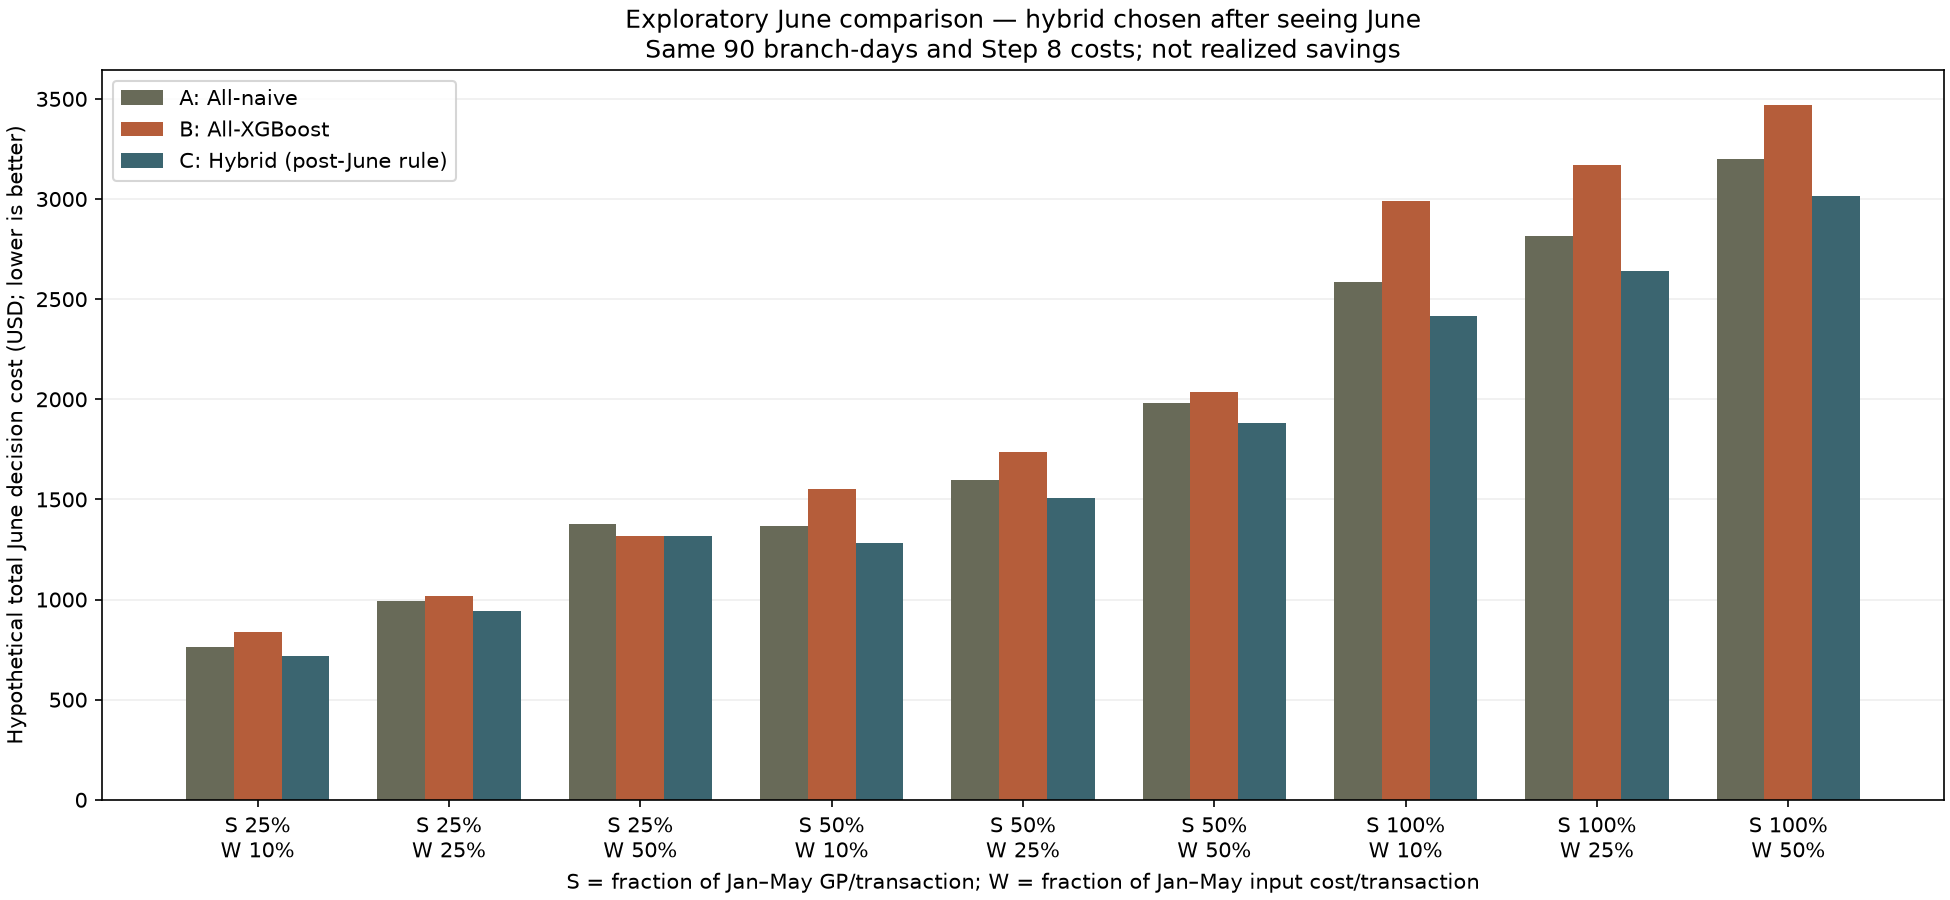

In [6]:
display(Image(filename=str(ROOT/'figures/hybrid_forecasting/policy_cost_comparison.png')))

## 6. Interpretation: hindsight advantage is not validation

The mapping deliberately combines June's branch winners, and each branch's chosen model already won all nine Step 8 cost settings. Adding those selected costs mechanically favors the hybrid on these same observations. Nine scenarios reuse the same errors; they are not nine independent confirmations.

Evaluate whether the apparent advantage is large enough to pay for maintaining and monitoring a branch-specific policy. No model operating costs, real preparation batches, SKU mix, actual capacity, salvage, queues or recaptured demand are measured. Historical observed sales may already be constrained demand. None of these comparisons validates a response to war.

In [7]:
print('Apparent June advantage vs all-naive USD:',findings['improvementVsNaiveRangeUSD'])
print('Apparent June advantage vs all-XGBoost USD:',findings['improvementVsXGBoostRangeUSD'])
print('Apparent June advantage vs stronger uniform baseline USD:',findings['improvementVsBestUniformRangeUSD'])
display(overall[['Scenario','StrongestUniformBaseline','HybridImprovementVsBestUniformUSD','HybridReductionVsBestUniformFraction']].round(4))
print('Potential implementation/monitoring cost and out-of-period policy instability are not priced.')

Apparent June advantage vs all-naive USD: [44.65257863320744, 182.04866937460838]
Apparent June advantage vs all-XGBoost USD: [1.09003185820211, 572.6680224745132]
Apparent June advantage vs stronger uniform baseline USD: [1.09003185820211, 182.04866937460838]
Potential implementation/monitoring cost and out-of-period policy instability are not priced.


,Scenario,StrongestUniformBaseline,HybridImprovementVsBestUniformUSD,HybridReductionVsBestUniformFraction
0,S0.25_W0.1,A_AllNaive,44.6526,0.0587
1,S0.25_W0.25,A_AllNaive,49.8101,0.0502
2,S0.25_W0.5,B_AllXGBoost,1.0900,0.0008
3,S0.5_W0.1,A_AllNaive,85.8668,0.0627
4,S0.5_W0.25,A_AllNaive,91.0243,0.0569
5,S0.5_W0.5,A_AllNaive,99.6202,0.0502
6,S1_W0.1,A_AllNaive,168.2953,0.0651
7,S1_W0.25,A_AllNaive,173.4528,0.0616
8,S1_W0.5,A_AllNaive,182.0487,0.0569


## 7. Future experiment: choose the branch rule on validation only

1. Before opening a future test period, predefine the candidate models, capacity/rounding policy and operational penalty accounting. If several cost scenarios remain relevant, predefine how they are weighted or use a predeclared robust criterion; do not select the favorable scenario afterward.
2. Use earlier rolling validation predictions to choose the model per branch, with economics known before each validation forecast. For the original timeline, existing May predictions and **Jan–Apr** economics could support a branch-selection rule. Jan–May monetary averages would leak into a supposedly prospective May selection. Predeclare simple-model tie/weak-evidence fallback behavior.
3. Freeze the rule, and any permitted training/refit cutoff, before genuinely later unseen observations. June has already been examined: a new May selection now would not turn this project's June into independent validation. Obtain later data or a prospective shadow pilot.
4. Compare the locked policy against all-naive and all-XGBoost on matched future branch-days. Report paired uncertainty respecting temporal/shared-branch dependence and actual stockout/waste/service/implementation costs. Further tuning requires another test period.

This notebook does **not** select a new validation rule or claim a branch hybrid is proven superior. It supplies a transparent exploratory target for that future experiment.

In [8]:
assert before=={str(p):sha(p) for p in locked}
assert len(costs)==108 and len(comparison)==36
for branch,expected in [('Harbour','AllNaiveCostUSD'),('Garden','AllXGBoostCostUSD'),('Uptown','AllXGBoostCostUSD')]:
    rows=comparison[comparison.Branch==branch]
    np.testing.assert_allclose(rows.HybridCostUSD,rows[expected])
print('PASS: source, saved models/predictions, selection lock and all Step 8 evidence unchanged.')
print('Outputs:',OUT)
print('Decision: prospectively test this hypothesis; no deployment or realized-savings claim.')

PASS: source, saved models/predictions, selection lock and all Step 8 evidence unchanged.
Outputs: /Users/aya/Downloads/hack/reports/hybrid_forecasting
Decision: prospectively test this hypothesis; no deployment or realized-savings claim.
